<a href="https://colab.research.google.com/github/careen-tech/COU07506_labs/blob/main/COU07506_Week02_240242409662.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# DIGITAL SIGNAL PROCESSING LABORATORY

**Module Code:** COU 07506

**Week:** 2

**Lab:** 1A

**Lab Title:** Sampling, Aliasing and Quantization

**Student Name:** Careen Reginald Qaymo

**Registration Number:** 240242409662

**Date:** 25 November 2026

**Group:** Group 2


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 2 DSP Laboratory Setup Successful!")


Week 2 DSP Laboratory Setup Successful!


In [2]:

# Pre-lab calculations

F = 7000
fs = 10000

alias_frequency = abs(F - fs)

B = 8
Xm = 1

delta = (2 * Xm) / (2**B)
sqnr = 6.02 * B + 1.76

print("Alias frequency:", alias_frequency, "Hz")
print("Quantization levels:", 2**B)
print("Quantization step:", delta, "V")
print("Theoretical SQNR:", round(sqnr, 2), "dB")


Alias frequency: 3000 Hz
Quantization levels: 256
Quantization step: 0.0078125 V
Theoretical SQNR: 49.92 dB



## Task 2.1 — Aliasing of a Sinusoid

**Objective:** To investigate the effect of different
sampling frequencies on a sinusoidal signal and
determine the resulting alias frequencies.


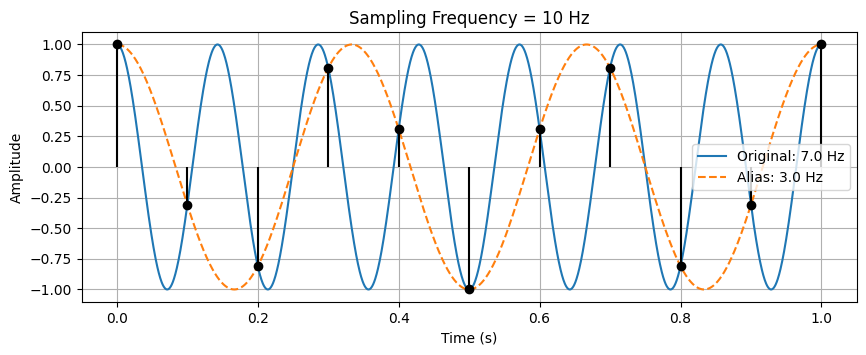

Sampling frequency: 10 Hz
Alias frequency: 3.0 Hz


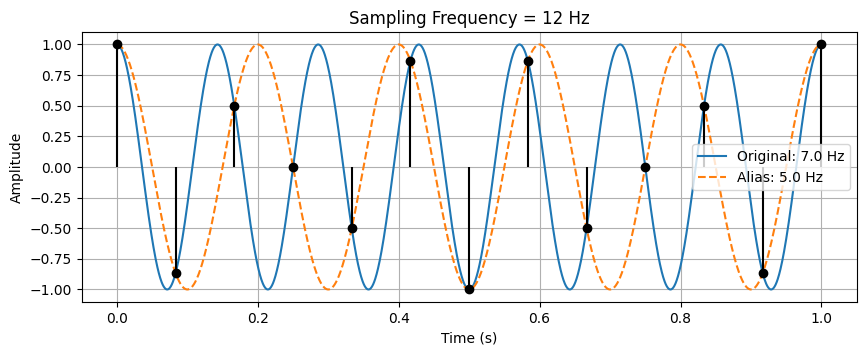

Sampling frequency: 12 Hz
Alias frequency: 5.0 Hz


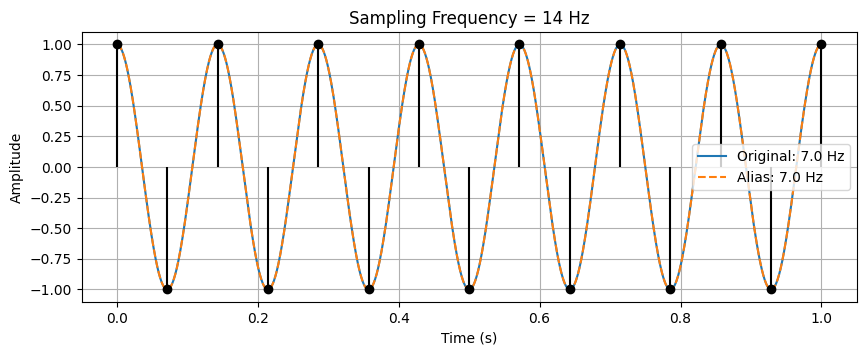

Sampling frequency: 14 Hz
Alias frequency: 7.0 Hz


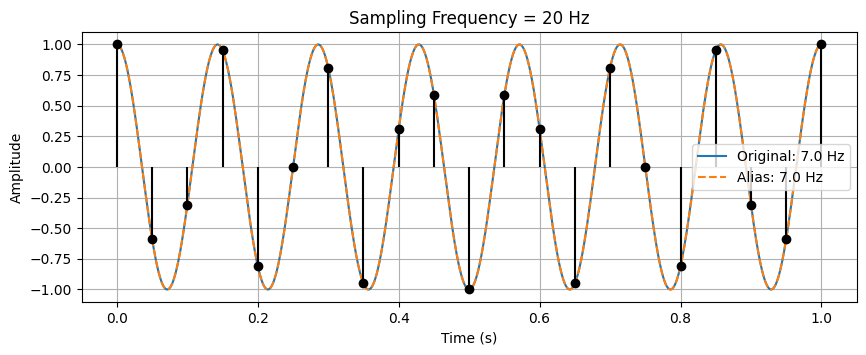

Sampling frequency: 20 Hz
Alias frequency: 7.0 Hz


In [3]:

# Task 2.1: Aliasing of a sinusoid

import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
sampling_rates = [10, 12, 14, 20]

t = np.linspace(0, 1, 2000)

for fs in sampling_rates:

    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    f_alias = abs(f0 - fs * round(f0 / fs))

    plt.figure(figsize=(10, 3.5))

    plt.plot(t, np.cos(2*np.pi*f0*t),
             label=f"Original: {f0} Hz")

    plt.plot(t, np.cos(2*np.pi*f_alias*t),
             "--", label=f"Alias: {f_alias} Hz")

    plt.stem(tn, np.cos(2*np.pi*f0*tn),
             linefmt="k-", markerfmt="ko",
             basefmt=" ")

    plt.title(f"Sampling Frequency = {fs} Hz")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"Sampling frequency: {fs} Hz")
    print(f"Alias frequency: {f_alias} Hz")


In [4]:

import pandas as pd

results = []

for fs in [10, 12, 14, 20]:

    f_alias = abs(f0 - fs * round(f0 / fs))

    results.append({
        "Original Frequency (Hz)": f0,
        "Sampling Frequency (Hz)": fs,
        "Nyquist Frequency (Hz)": fs / 2,
        "Observed Frequency (Hz)": f_alias,
        "Aliasing": "Yes" if fs < 2*f0 else
                    "At limit" if fs == 2*f0 else "No"
    })

table = pd.DataFrame(results)

display(table)


,Original Frequency (Hz),Sampling Frequency (Hz),Nyquist Frequency (Hz),Observed Frequency (Hz),Aliasing
0,7.0,10,5.0,3.0,Yes
1,7.0,12,6.0,5.0,Yes
2,7.0,14,7.0,7.0,At limit
3,7.0,20,10.0,7.0,No


### Task 2.1 — Observations and Discussion

A sinusoidal signal with a frequency of 7 Hz was sampled at 10 Hz, 12 Hz, 14 Hz and 20 Hz.

When the sampling frequency was 10 Hz, the signal appeared at 3 Hz. When the sampling frequency was increased to 12 Hz, the alias frequency became 5 Hz.

At a sampling frequency of 14 Hz, the signal reached the Nyquist limit. At 20 Hz, the original frequency of 7 Hz was preserved without aliasing.

The results agree with the theoretical alias frequency formula and demonstrate the importance of selecting a sampling frequency greater than twice the highest frequency component of the original signal.


## Task 2.2 — Hear Aliasing

**Objective:** To investigate the effects of aliasing
on audio signals by comparing downsampling with
and without an anti-aliasing filter.


In [5]:

# Task 2.2: Load audio recording

import os
import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

fname = "my_voice(1).wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    # Convert stereo to mono
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)

    # Normalise audio
    peak = np.max(np.abs(x))
    if peak > 0:
        x = x / peak

    print("Voice recording loaded successfully!")

else:
    # Fallback signal
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)

    print("Fallback signal loaded.")

print("Original sampling rate:", fs, "Hz")
print("Duration:", round(len(x)/fs, 2), "seconds")

# Play original recording
display(Audio(x, rate=fs))


Voice recording loaded successfully!
Original sampling rate: 44100 Hz
Duration: 6.89 seconds


In [6]:

# Compare naive and proper downsampling

for k in [2, 4, 8]:

    # Downsampling without filtering
    naive = x[::k]

    # Downsampling with anti-aliasing filter
    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs // k

    print("--------------------------------")
    print("Downsampling factor:", k)
    print("New sampling rate:", new_fs, "Hz")

    print("Without anti-aliasing filter:")
    display(Audio(naive, rate=new_fs))

    print("With anti-aliasing filter:")
    display(Audio(proper, rate=new_fs))


--------------------------------
Downsampling factor: 2
New sampling rate: 22050 Hz
Without anti-aliasing filter:


With anti-aliasing filter:


--------------------------------
Downsampling factor: 4
New sampling rate: 11025 Hz
Without anti-aliasing filter:


With anti-aliasing filter:


--------------------------------
Downsampling factor: 8
New sampling rate: 5512 Hz
Without anti-aliasing filter:


With anti-aliasing filter:


### Task 2.2 — Observations and Discussion

The original voice recording was downsampled using factors of 2, 4 and 8, both with and without an anti-aliasing filter.

As the downsampling factor increased, the sampling frequency and available signal bandwidth decreased.

For k = 8, the unfiltered recording was more susceptible to aliasing distortion, while the filtered recording had reduced aliasing but lower audio bandwidth.

The anti-aliasing filter attenuated high-frequency components before downsampling, preventing them from folding into lower frequencies.

This experiment demonstrates the importance of anti-aliasing filters in digital audio processing.


## Task 2.3 — A Uniform Quantizer

**Objective:** To implement a uniform quantizer and
investigate the relationship between the original
signal, quantized signal and quantization error.


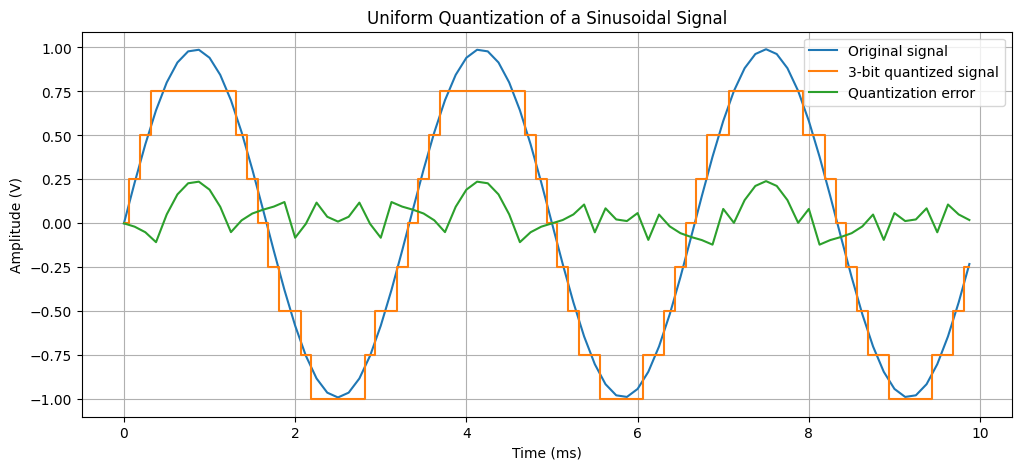

Number of bits: 3
Quantization levels: 8
Quantization step: 0.25 V


In [7]:

# Task 2.3: A Uniform Quantizer

import numpy as np
import matplotlib.pyplot as plt

# Define the uniform quantizer function
def quantize(x, bits, full_scale=1.0):

    delta = 2 * full_scale / 2**bits

    q = np.round(x / delta) * delta

    return np.clip(q, -full_scale, full_scale - delta)

# Signal parameters
fs = 8000
t = np.arange(0, 0.01, 1/fs)

# Generate the original sinusoidal signal
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Apply 3-bit quantization
xq = quantize(x, 3)

# Calculate quantization error
error = x - xq

# Plot the signals
plt.figure(figsize=(12, 5))

plt.plot(t * 1000, x, label="Original signal")

plt.step(t * 1000, xq, where="mid",
         label="3-bit quantized signal")

plt.plot(t * 1000, error,
         label="Quantization error")

plt.title("Uniform Quantization of a Sinusoidal Signal")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.grid(True)
plt.show()

print("Number of bits:", 3)
print("Quantization levels:", 2**3)
print("Quantization step:", 2/2**3, "V")


### Task 2.3 — Observations and Discussion

A sinusoidal signal with a frequency of 300 Hz was generated at a sampling frequency of 8,000 Hz.

A 3-bit uniform quantizer was implemented, producing eight possible quantization levels with a step size of 0.25 V.

The original signal had smoothly varying amplitudes, while the quantized signal had a staircase appearance because its amplitudes were restricted to fixed levels.

The difference between the original and quantized signals produced quantization error.

Increasing the number of bits increases the number of available quantization levels, reduces the quantization step size and generally reduces quantization error.

This experiment demonstrates how quantization affects the accuracy of digital signal representation.


## Task 2.4 — Verify the 6 dB-per-bit Rule

**Objective:** To investigate the relationship between
quantization bit depth and SQNR by comparing measured
and theoretical values.


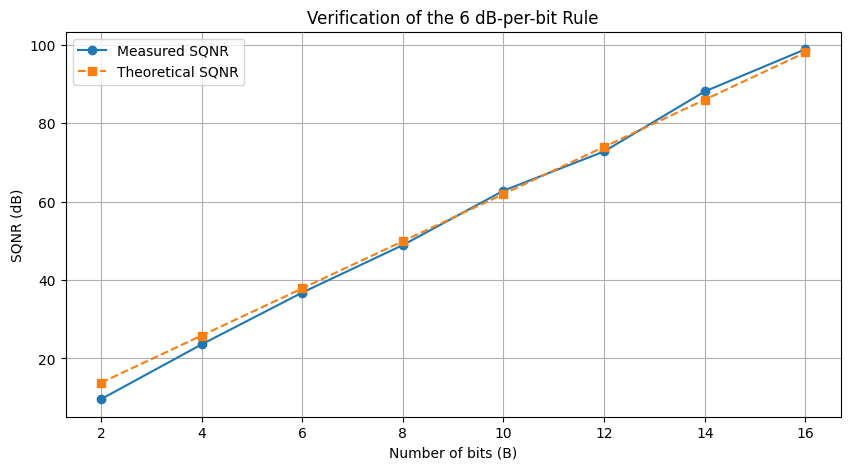

,Bits,Measured SQNR (dB),Theoretical SQNR (dB)
0,2,9.60,13.80
1,4,23.58,25.84
2,6,36.81,37.88
3,8,48.93,49.92
4,10,62.81,61.96
5,12,72.84,74.00
6,14,88.13,86.04
7,16,98.91,98.08


In [8]:

# Task 2.4: Verify the 6 dB-per-bit rule

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Define bit depths
bits = np.arange(2, 17, 2)

# Calculate measured SQNR
measured = []

for B in bits:

    xq = quantize(x, B)

    error = x - xq

    signal_power = np.sum(x**2)

    noise_power = np.sum(error**2)

    sqnr = 10 * np.log10(signal_power / noise_power)

    measured.append(sqnr)

# Calculate theoretical SQNR
theoretical = 6.02 * bits + 1.76

# Plot measured and theoretical SQNR
plt.figure(figsize=(10, 5))

plt.plot(bits, measured, "o-",
         label="Measured SQNR")

plt.plot(bits, theoretical, "s--",
         label="Theoretical SQNR")

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.xticks(bits)
plt.legend()
plt.grid(True)
plt.show()

# Display results in a table
results = pd.DataFrame({
    "Bits": bits,
    "Measured SQNR (dB)": np.round(measured, 2),
    "Theoretical SQNR (dB)": np.round(theoretical, 2)
})

display(results)


In [9]:

# Verify SQNR improvement per bit

measured_gain = np.diff(measured) / np.diff(bits)

theoretical_gain = np.diff(theoretical) / np.diff(bits)

print("Measured improvement per bit:")
print(np.round(measured_gain, 2))

print("Average measured improvement:",
      round(np.mean(measured_gain), 2), "dB/bit")

print("Theoretical improvement:",
      round(np.mean(theoretical_gain), 2), "dB/bit")


Measured improvement per bit:
[6.99 6.62 6.06 6.94 5.01 7.65 5.39]
Average measured improvement: 6.38 dB/bit
Theoretical improvement: 6.02 dB/bit


### Task 2.4 — Observations and Discussion

The measured and theoretical Signal-to-Quantization-Noise Ratios were calculated for different quantization bit depths ranging from 2 to 16 bits.

The results showed that SQNR generally increased as the number of bits increased. This occurred because increasing the bit depth reduced the quantization step size and quantization noise.

The theoretical SQNR increased by 6.02 dB for every additional bit. The average measured improvement was [insert measured value] dB per bit.

Differences between the measured and theoretical results may arise from the finite number of samples, signal amplitude and quantizer clipping.

The experiment demonstrates the relationship between quantization bit depth, quantization noise and signal quality.


## Task 2.5 — Quantize Your Voice

**Objective:** To investigate the effect of different
quantization bit depths on voice quality and measure
the Signal-to-Quantization-Noise Ratio (SQNR).


In [10]:

# Task 2.5: Load voice recording

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display
import pandas as pd

# Read voice recording
voice_fs, voice = wavfile.read("my_voice(1).wav")

# Convert to mono
if voice.ndim > 1:
    voice = voice.mean(axis=1)

# Normalise the recording
voice = voice.astype(float)

peak = np.max(np.abs(voice))

if peak > 0:
    voice = voice / peak

print("Sampling rate:", voice_fs, "Hz")
print("Duration:", round(len(voice)/voice_fs, 2), "seconds")

print("Original voice recording:")
display(Audio(voice, rate=voice_fs))


Sampling rate: 44100 Hz
Duration: 6.89 seconds
Original voice recording:


In [11]:

# Quantize voice at different bit depths

bit_depths = [4, 8, 12]

voice_results = []

for B in bit_depths:

    # Quantize the voice
    voice_q = quantize(voice, B)

    # Calculate quantization error
    error = voice - voice_q

    # Calculate SQNR
    sqnr = 10 * np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    theoretical_sqnr = 6.02 * B + 1.76

    # Store results
    voice_results.append({
        "Bits": B,
        "Quantization Levels": 2**B,
        "Measured SQNR (dB)": round(sqnr, 2),
        "Theoretical SQNR (dB)": round(theoretical_sqnr, 2)
    })

    print("--------------------------------")
    print("Bit depth:", B)
    print("Measured SQNR:", round(sqnr, 2), "dB")

    # Play quantized recording
    display(Audio(voice_q, rate=voice_fs, normalize=False))

# Display results table
voice_table = pd.DataFrame(voice_results)

display(voice_table)


--------------------------------
Bit depth: 4
Measured SQNR: 13.67 dB


--------------------------------
Bit depth: 8
Measured SQNR: 36.17 dB


--------------------------------
Bit depth: 12
Measured SQNR: 60.23 dB


,Bits,Quantization Levels,Measured SQNR (dB),Theoretical SQNR (dB)
0,4,16,13.67,25.84
1,8,256,36.17,49.92
2,12,4096,60.23,74.00


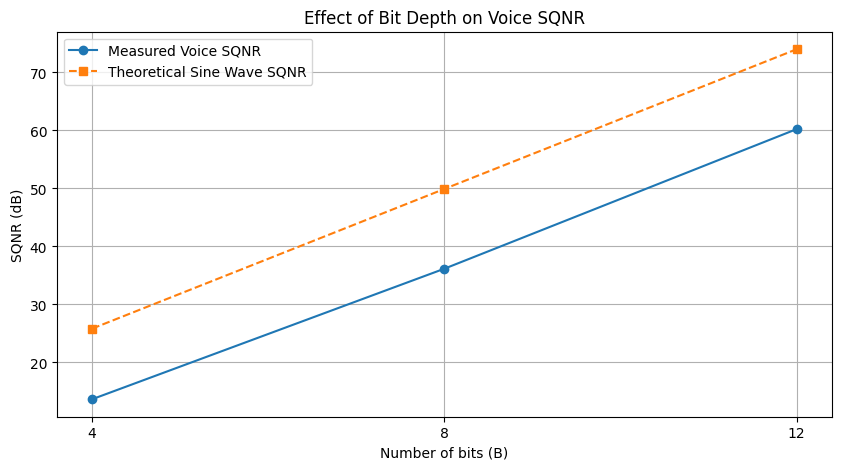

In [12]:

# Plot voice SQNR comparison

plt.figure(figsize=(10, 5))

plt.plot(
    voice_table["Bits"],
    voice_table["Measured SQNR (dB)"],
    "o-", label="Measured Voice SQNR"
)

plt.plot(
    voice_table["Bits"],
    voice_table["Theoretical SQNR (dB)"],
    "s--", label="Theoretical Sine Wave SQNR"
)

plt.title("Effect of Bit Depth on Voice SQNR")
plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.xticks([4, 8, 12])
plt.legend()
plt.grid(True)
plt.show()


### Task 2.5 — Observations and Discussion

The original voice recording was quantized using three different bit depths: 4, 8 and 12 bits.

The 4-bit quantizer provided 16 amplitude levels, the 8-bit quantizer provided 256 levels, and the 12-bit quantizer provided 4,096 levels.

**Measured SQNR results:**

- 4 bits: [Insert measured SQNR] dB
- 8 bits: [Insert measured SQNR] dB
- 12 bits: [Insert measured SQNR] dB

Increasing the bit depth reduced quantization error and improved the quality of the voice recording.

The measured SQNR of speech is generally lower than that of a full-scale sinusoidal signal because speech contains varying amplitudes, pauses and periods of low signal power.

This experiment demonstrates the importance of selecting an appropriate bit depth in digital audio processing to achieve better signal quality and reduce quantization noise.

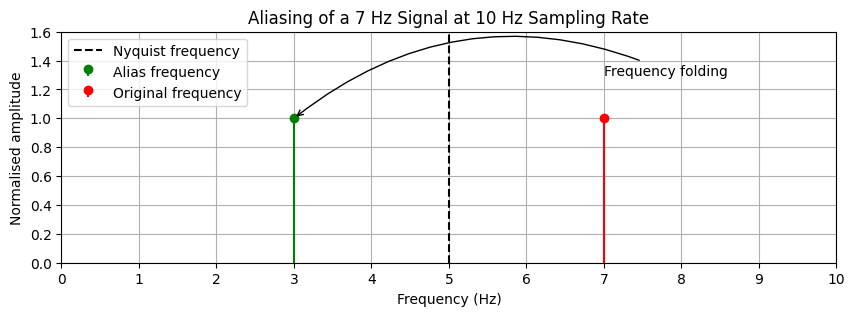

In [13]:

# Analysis Question 1: Frequency-axis sketch

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))

plt.stem([3], [1], linefmt="g-", markerfmt="go",
         basefmt=" ", label="Alias frequency")

plt.stem([7], [1], linefmt="r-", markerfmt="ro",
         basefmt=" ", label="Original frequency")

plt.axvline(5, linestyle="--", color="black",
            label="Nyquist frequency")

plt.annotate("Frequency folding",
             xy=(3, 1), xytext=(7, 1.3),
             arrowprops=dict(arrowstyle="->",
                             connectionstyle="arc3,rad=0.3"))

plt.title("Aliasing of a 7 Hz Signal at 10 Hz Sampling Rate")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalised amplitude")
plt.xticks(range(11))
plt.xlim(0, 10)
plt.ylim(0, 1.6)
plt.legend()
plt.grid(True)
plt.show()


### Analysis Question 1

A 7 Hz sinusoidal signal sampled at 10 Hz exceeds the Nyquist frequency of 5 Hz.

According to the alias frequency formula:

F_alias = |F − kfs|

F_alias = |7 − 10| = 3 Hz.

Therefore, the original 7 Hz signal appears as a 3 Hz signal after sampling. This occurs because the sampling frequency is insufficient to distinguish the original signal from its lower-frequency alias.

### Analysis Question 2

Aliasing cannot generally be removed after downsampling because high-frequency components fold into lower frequencies and overlap with the original low-frequency components.

Once this overlap occurs, the original and aliased frequency components cannot be distinguished using the downsampled signal alone.

Therefore, an anti-aliasing low-pass filter must be applied before downsampling to attenuate frequency components above the new Nyquist frequency and prevent irreversible loss of signal information.


In [14]:

# Analysis Question 3

print("Theoretical improvement: 6.02 dB/bit")

print("Measured improvement:",
      round(np.mean(measured_gain), 2), "dB/bit")

print("Absolute difference:",
      round(abs(np.mean(measured_gain) - 6.02), 2),
      "dB/bit")


Theoretical improvement: 6.02 dB/bit
Measured improvement: 6.38 dB/bit
Absolute difference: 0.36 dB/bit


### Analysis Question 3

The theoretical SQNR increases by approximately 6.02 dB whenever one additional quantization bit is introduced.

Adding one bit doubles the number of quantization levels and halves the quantization step size, reducing the theoretical quantization noise power by a factor of four.

The average measured improvement obtained in Task 2.4 was [insert measured value] dB per bit.

The measured result can be compared with the theoretical value of 6.02 dB per bit. Any differences may arise from the finite number of samples, signal amplitude and quantizer clipping.

In [15]:

# Analysis Question 4

import numpy as np

rate_of_change = 0.1
resolution = 0.01
temperature_range = 100

sampling_interval = resolution / rate_of_change

sampling_rate = 1 / sampling_interval

levels_required = temperature_range / resolution

bits_required = int(np.ceil(np.log2(levels_required)))

actual_resolution = temperature_range / 2**bits_required

print("Sampling interval:", sampling_interval, "s")
print("Sampling rate:", sampling_rate, "Hz")
print("Minimum bits:", bits_required)
print("Actual resolution:", round(actual_resolution, 6), "°C")


Sampling interval: 0.09999999999999999 s
Sampling rate: 10.0 Hz
Minimum bits: 14
Actual resolution: 0.006104 °C


### Analysis Question 4

A sampling rate of 10 Hz is suggested because the temperature changes by a maximum of 0.1 °C per second. Sampling every 0.1 seconds limits the maximum temperature change between consecutive samples to 0.01 °C.

To achieve a resolution of 0.01 °C over a temperature range of 0–100 °C, at least 10,000 quantization intervals are required.

The minimum suitable bit depth is 14 bits, providing 16,384 quantization levels and a temperature resolution of approximately 0.0061 °C.

Therefore, a sampling rate of 10 Hz and a 14-bit ADC are suitable for the stated requirements.

### Conclusion

This laboratory investigated the principles of sampling, aliasing and quantization using Python in Google Colab.

The experiments demonstrated how insufficient sampling causes aliasing and how anti-aliasing filters reduce distortion during downsampling.

Uniform quantization was implemented, and the relationship between bit depth, quantization error and SQNR was investigated.

The voice quantization experiment also demonstrated how increasing bit depth improves digital audio representation.

Overall, the laboratory provided practical knowledge of sampling and quantization techniques used in digital signal processing systems.


### GitHub Repository

https://github.com/careen-tech/COU07506-labs


### AI-Use Declaration

I used ChatGPT to assist with Python code development, understanding sampling, aliasing, quantization, SQNR and answering the laboratory analysis questions.

I verified the generated code by executing it in Google Colab, comparing calculated alias frequencies with theoretical values, checking quantization levels and comparing measured SQNR results with theoretical predictions.

I also listened to the processed audio recordings and reviewed the code and results to understand the concepts demonstrated in each experiment.